# 06 · Ramadan: jam kehadiran dan kategori tempat

## Cara membaca

Pada kunjungan siang kita melihat **asal mana terhubung dengan tujuan mana**.
Sekarang kita melihat **kapan perangkat tercatat**, lalu indikator kategori tempat dari Google.
Banguntapan dan Depok dipilih karena sudah menjadi contoh sebelumnya, bukan karena kenaikan terbesar.

Di sini, kehadiran berarti perangkat tercatat di suatu wilayah pada suatu jam. Satu perangkat
dapat dihitung pada beberapa jam. Ini bukan perangkat yang pasti berumah di wilayah itu,
bukan hitungan perjalanan, dan tidak mengikuti kelanjutan perjalanan pada analisis kunjungan siang.

Ukuran utama: dari seluruh catatan perangkat per jam dalam sehari, berapa persen berada pada
**03.00–04.59 WIB**. Hitung per hari dan wilayah, lalu rata-ratakan; setiap hari berbobot sama.
Kenaikan porsi tidak membuktikan kenaikan jumlah perangkat, perjalanan, atau aktivitas di luar rumah.

Bandingkan **12 Maret–1 April** dengan **3–23 April 2022**. Masing-masing 21 hari dengan tiga
Senin, tiga Selasa, dan seterusnya. Tanggal 2 April adalah transisi: sebagian mulai Ramadan
pada tanggal itu, pemerintah mulai 3 April menurut kalender repo. Hari libur tetap masuk
perbandingan utama agar komposisi hari seimbang; pemeriksaan khusus mengeluarkan pasangan Jumat.

Google mencakup DIY, bukan kedua wilayah contoh. Indeksnya adalah perubahan persentase terhadap
median hari sejenis 3 Januari–6 Februari 2020. Residential mengukur waktu di rumah;
kategori lainnya berkaitan dengan kunjungan. Selisih antarperiode adalah **poin indeks**,
bukan persentase penurunan jumlah kunjungan dari periode sebelumnya.

Sumber hanya dari repo: JogjaPulse [README bagian 4.2, 5–6](https://zenodo.org/records/23157460),
Google CMR DIY, dan kalender yang sudah tersedia. Definisi Google:
[dokumentasi sumber](https://www.google.com/covid19/mobility/data_documentation.html).
Kode bersama: `src/applied.py`; sumber mentah dan hash dapat ditelusuri pada tabel provenance.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/config.py').exists())
sys.path.insert(0, str(ROOT/'src'))
from applied import ramadan_analysis, RAMADAN_FOCUS_CODES, RAMADAN_MAIN_CATEGORIES
from config import PROCESSED, FIGURES, CALENDAR_CSV, GOOGLE_CATEGORIES
h = pd.read_parquet(PROCESSED/'hourly_kapanewon.parquet')
d = pd.read_parquet(PROCESSED/'daily_diy.parquet').set_index('date')
cal = pd.read_csv(CALENDAR_CSV, parse_dates=['date'])
start = cal.loc[cal.name.str.contains('government'), 'date'].iloc[0]
r = ramadan_analysis(h, d, start)
wide = ramadan_analysis(h, d, start, hours=(3,4,5))
no_friday = ramadan_analysis(h, d, start, exclude_paired_fridays=True)
assert d.loc[r['before'].union(r['during']), 'panel_segment'].eq('S3 16 Feb-Apr').all()
focus = r['summary'].set_index('kapanewon_code').loc[list(RAMADAN_FOCUS_CODES)]
g = r['google'].set_index('category')
TABLES = ROOT/'reports/tables'; TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
for name in ['coverage','area_day','summary','weekly','profiles','google','google_days','midnight_summary']:
    r[name].to_csv(TABLES/f'ramadan_{name}.csv', index=False)
sensitivity = pd.concat([frame.assign(scenario=label) for label,frame in [
    ('03-04 primary',r['summary']),('03-05',wide['summary']),
    ('exclude paired Fridays',no_friday['summary']),('denominator excludes 00-02',r['midnight_summary'])]])
sensitivity.to_csv(TABLES/'ramadan_sensitivity.csv',index=False)
no_friday['google'].to_csv(TABLES/'ramadan_google_no_friday.csv', index=False)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False})
BEFORE='#737373'; DURING='#0F766E'; GOOGLE='#C2410C'
def save(fig,name):
    fig.savefig(FIGURES/f'ramadan_{name}.png',bbox_inches='tight',facecolor='white')
def idnum(v):return f'{v:.1f}'.replace('.',',')
labels={'parks':'Taman (parks)','retail_and_recreation':'Retail / rekreasi',
        'residential':'Waktu di rumah (residential)'}

## 1. Porsi pencatatan dini hari lebih tinggi di kedua wilayah contoh

Panel kiri memakai rata-rata porsi harian di setiap wilayah, bukan jumlah orang.
Panel kanan memakai selisih indeks Google tingkat DIY. Kedua panel mempunyai ukuran
dan cakupan berbeda; jangan membandingkan tinggi batangnya sebagai besaran yang sama.

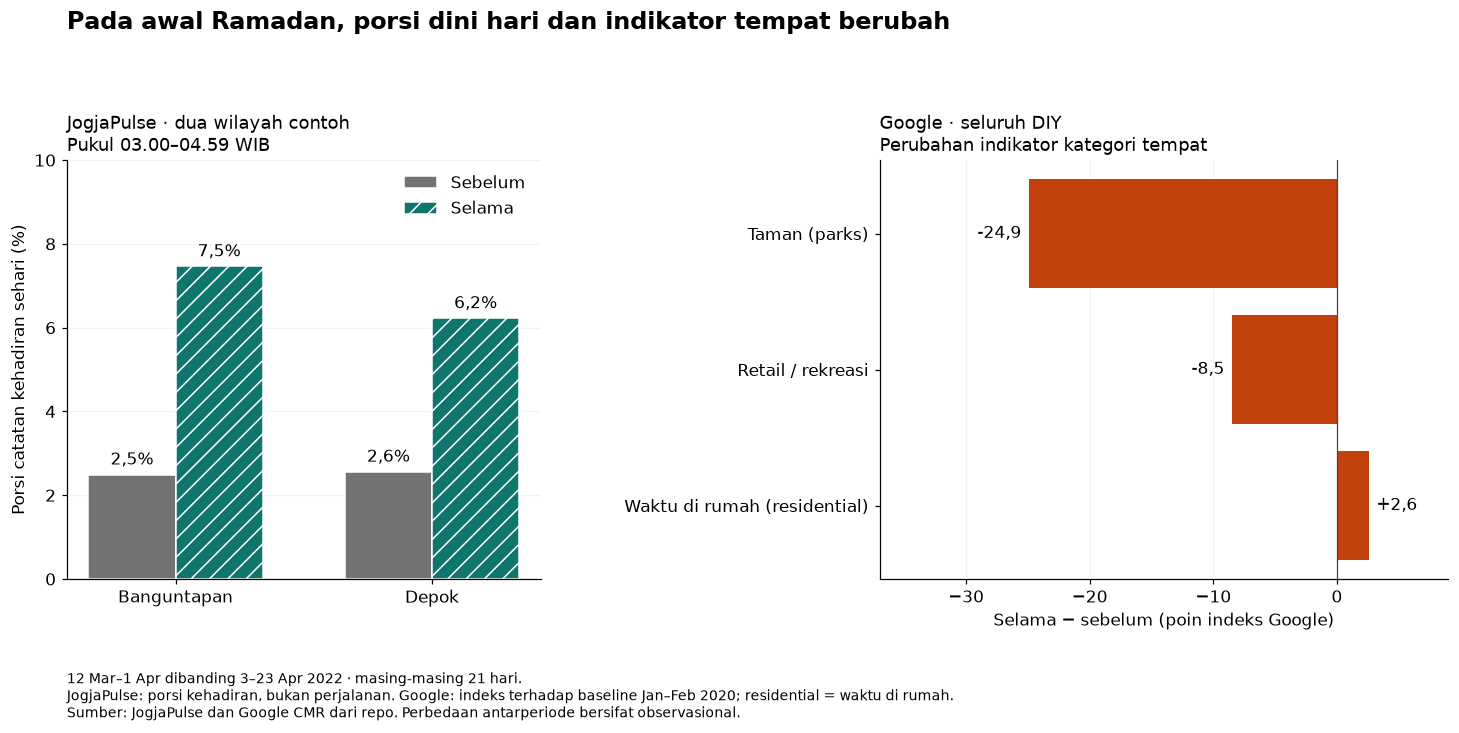

period,Wilayah,Sebelum (%),Selama (%),Selisih (poin persentase)
34.02.12,BANGUNTAPAN,2.49,7.46,4.97
34.04.07,DEPOK,2.56,6.22,3.67


In [2]:
fig, axes = plt.subplots(1,2,figsize=(13.8,6.8),gridspec_kw={'width_ratios':[1,1.2]})
x=np.arange(2)
for offset,col,label,color,hatch in [(-.17,'before','Sebelum',BEFORE,''),(.17,'during','Selama',DURING,'//')]:
    vals=focus[col].to_numpy()
    bars=axes[0].bar(x+offset,vals,.34,label=label,color=color,hatch=hatch,edgecolor='white')
    axes[0].bar_label(bars,labels=[idnum(v)+'%' for v in vals],padding=4,fontsize=11)
axes[0].set_xticks(x,focus.kapanewon.str.title())
axes[0].set_ylim(0,10)
axes[0].set_ylabel('Porsi catatan kehadiran sehari (%)')
axes[0].set_title('JogjaPulse · dua wilayah contoh\nPukul 03.00–04.59 WIB',loc='left',fontsize=12)
axes[0].legend(frameon=False)
plot=g.loc[list(RAMADAN_MAIN_CATEGORIES)].iloc[::-1]
bars=axes[1].barh([labels[c] for c in plot.index],plot.change_pp,color=GOOGLE)
axes[1].bar_label(bars,labels=[f'{v:+.1f}'.replace('.',',') for v in plot.change_pp],padding=5,fontsize=11)
axes[1].axvline(0,color='#444444',lw=.8)
axes[1].set_xlim(-37,9)
axes[1].set_xlabel('Selama − sebelum (poin indeks Google)')
axes[1].set_title('Google · seluruh DIY\nPerubahan indikator kategori tempat',loc='left',fontsize=12)
for ax in axes:ax.grid(axis='y' if ax==axes[0] else 'x',alpha=.15);ax.set_axisbelow(True)
fig.suptitle('Pada awal Ramadan, porsi dini hari dan indikator tempat berubah',
             x=.06,ha='left',fontsize=16,weight='bold')
fig.text(.06,.035,'12 Mar–1 Apr dibanding 3–23 Apr 2022 · masing-masing 21 hari.\n'
         'JogjaPulse: porsi kehadiran, bukan perjalanan. Google: indeks terhadap baseline Jan–Feb 2020; residential = waktu di rumah.\n'
         'Sumber: JogjaPulse dan Google CMR dari repo. Perbedaan antarperiode bersifat observasional.',fontsize=9)
fig.subplots_adjust(left=.06,right=.97,top=.78,bottom=.22,wspace=.65)
save(fig,'story');plt.show()
display(focus[['kapanewon','before','during','change_pp']].rename(columns={'kapanewon':'Wilayah','before':'Sebelum (%)','during':'Selama (%)','change_pp':'Selisih (poin persentase)'}).rename_axis(None).round(2))

## 2. Google memberi sudut pandang kategori tempat

Parks dan retail/rekreasi memiliki indeks rata-rata lebih rendah, sedangkan residential lebih tinggi.
Artinya indikator kunjungan dua kategori itu lebih rendah dan indikator waktu di rumah lebih tinggi
dibanding periode sebelum Ramadan. Ini bukan bukti bahwa perangkat yang muncul dini hari kemudian
tinggal di rumah, dan bukan validasi angka JogjaPulse satu per satu.

In [3]:
display(g.loc[list(RAMADAN_MAIN_CATEGORIES), ['before','during','change_pp']].rename(index=labels).rename_axis('Kategori').rename(
    columns={'before':'Indeks sebelum','during':'Indeks selama','change_pp':'Selisih poin indeks'}).round(2))

period,Indeks sebelum,Indeks selama,Selisih poin indeks
Kategori,,,
Taman (parks),21.57,-3.33,-24.90
Retail / rekreasi,5.10,-3.38,-8.48
Waktu di rumah (residential),14.81,17.38,2.57


## Kesimpulan yang dapat diceritakan

Cerita ini membahas tiga minggu pertama Ramadan 2022, bukan seluruh Ramadan atau Lebaran.

In [4]:
story = f"""Setelah melihat hubungan kunjungan siang antarwilayah, kami melihat waktu pencatatan
perangkat di Banguntapan dan Depok. Selama tiga minggu pertama Ramadan, porsi catatan pukul
03.00–04.59 lebih tinggi: Banguntapan dari {idnum(focus.loc['34.02.12','before'])}% menjadi
{idnum(focus.loc['34.02.12','during'])}%, dan Depok dari {idnum(focus.loc['34.04.07','before'])}%
menjadi {idnum(focus.loc['34.04.07','during'])}%.

Pada periode yang sama, Google tingkat DIY memperlihatkan indeks taman lebih rendah
{idnum(abs(g.loc['parks','change_pp']))} poin dan retail/rekreasi lebih rendah
{idnum(abs(g.loc['retail_and_recreation','change_pp']))} poin. Indeks waktu di rumah lebih tinggi
{idnum(g.loc['residential','change_pp'])} poin.

Jadi, pada sampel dan periode ini, perubahan terlihat pada kapan perangkat tercatat dan indikator
kategori tempat. Ketika mengamati pola Ramadan, jam dan kategori tempat perlu diperhatikan,
selain ringkasan harian. Kedua sumber memberi sudut pandang berbeda, bukan perjalanan orang yang sama.

Porsi dini hari sudah meningkat pada akhir periode sebelum Ramadan. Karena itu, kami menyebutnya
perbedaan selama periode Ramadan, bukan seluruhnya akibat Ramadan. Sahur dan penyesuaian rutinitas
merupakan kemungkinan penjelasan yang belum diuji. Data juga bisa berubah karena komposisi sampel
atau cara aplikasi mencatat lokasi. Kami belum dapat menyimpulkan kebutuhan transportasi atau peluang usaha.
"""
display(Markdown(story))
(ROOT/'docs/ramadan_insights.md').write_text('# Ramadan: narasi dan bukti\n\n'+story+
    '\n\nBukti dan definisi: `notebooks/06_ramadan.ipynb`, tabel `reports/tables/ramadan_*.csv`, '
    'grafik `reports/figures/ramadan_story.png`. Persentase JogjaPulse adalah porsi catatan perangkat per jam, '
    'bukan persentase penduduk. Selisih Google adalah poin indeks, bukan % perubahan jumlah kunjungan.',encoding='utf-8');

Setelah melihat hubungan kunjungan siang antarwilayah, kami melihat waktu pencatatan
perangkat di Banguntapan dan Depok. Selama tiga minggu pertama Ramadan, porsi catatan pukul
03.00–04.59 lebih tinggi: Banguntapan dari 2,5% menjadi
7,5%, dan Depok dari 2,6%
menjadi 6,2%.

Pada periode yang sama, Google tingkat DIY memperlihatkan indeks taman lebih rendah
24,9 poin dan retail/rekreasi lebih rendah
8,5 poin. Indeks waktu di rumah lebih tinggi
2,6 poin.

Jadi, pada sampel dan periode ini, perubahan terlihat pada kapan perangkat tercatat dan indikator
kategori tempat. Ketika mengamati pola Ramadan, jam dan kategori tempat perlu diperhatikan,
selain ringkasan harian. Kedua sumber memberi sudut pandang berbeda, bukan perjalanan orang yang sama.

Porsi dini hari sudah meningkat pada akhir periode sebelum Ramadan. Karena itu, kami menyebutnya
perbedaan selama periode Ramadan, bukan seluruhnya akibat Ramadan. Sahur dan penyesuaian rutinitas
merupakan kemungkinan penjelasan yang belum diuji. Data juga bisa berubah karena komposisi sampel
atau cara aplikasi mencatat lokasi. Kami belum dapat menyimpulkan kebutuhan transportasi atau peluang usaha.


## Lampiran: pemeriksaan pola dan keterbatasan

Semua 42 hari harus lengkap 24 jam agar wilayah masuk. Hanya empat wilayah memenuhi syarat,
bukan seluruh DIY. Dua wilayah lain ditampilkan agar cakupan tidak tersembunyi.
Kenaikan 03–04 di Gondomanan berubah arah jika jam 05 dimasukkan atau pembagi tengah malam
dikeluarkan. Jadi kesimpulan utama dibatasi pada Banguntapan dan Depok.

In [5]:
display(r['coverage'].loc[r['coverage'].eligible])
display(sensitivity[['kapanewon','scenario','before','during','change_pp']].round(2))
display(r['google'].round(2))
display(no_friday['google'].round(2))
# A headline must retain its direction under each specified diagnostic.
for frame in [wide['summary'],no_friday['summary'],r['midnight_summary']]:
    assert frame.set_index('kapanewon_code').loc[list(RAMADAN_FOCUS_CODES),'change_pp'].gt(0).all()
assert np.sign(g.loc[list(RAMADAN_MAIN_CATEGORIES),'change_pp']).equals(
    np.sign(no_friday['google'].set_index('category').loc[list(RAMADAN_MAIN_CATEGORIES),'change_pp']))

,kapanewon_code,kapanewon,kab_kota,complete_days_before,expected_days_before,complete_days_during,expected_days_during,eligible
22,34.02.12,BANGUNTAPAN,BANTUL,21,21,21,21,True
42,34.04.07,DEPOK,SLEMAN,21,21,21,21,True
48,34.04.13,SLEMAN,SLEMAN,21,21,21,21,True
62,34.71.10,GONDOMANAN,YOGYAKARTA,21,21,21,21,True


period,kapanewon,scenario,before,during,change_pp
0,BANGUNTAPAN,03-04 primary,2.49,7.46,4.97
1,DEPOK,03-04 primary,2.56,6.22,3.67
2,SLEMAN,03-04 primary,6.54,9.73,3.19
3,GONDOMANAN,03-04 primary,10.97,12.45,1.48
0,BANGUNTAPAN,03-05,5.26,10.34,5.08
1,DEPOK,03-05,5.00,8.69,3.68
2,SLEMAN,03-05,10.65,12.61,1.96
3,GONDOMANAN,03-05,15.49,15.45,-0.04
0,BANGUNTAPAN,exclude paired Fridays,2.47,7.44,4.98
1,DEPOK,exclude paired Fridays,2.55,6.18,3.63


period,category,before,during,change_pp
0,retail_and_recreation,5.10,-3.38,-8.48
1,grocery_and_pharmacy,13.71,8.81,-4.90
2,parks,21.57,-3.33,-24.90
3,transit_stations,-21.57,-32.71,-11.14
4,workplaces,3.90,3.33,-0.57
5,residential,14.81,17.38,2.57


period,category,before,during,change_pp
0,retail_and_recreation,4.90,-3.75,-8.65
1,grocery_and_pharmacy,13.40,8.70,-4.70
2,parks,21.35,-4.25,-25.60
3,transit_stations,-21.85,-33.00,-11.15
4,workplaces,3.90,5.70,1.80
5,residential,14.80,17.05,2.25


### Profil 24 jam dan perkembangan mingguan

Minggu merupakan tujuh hari berurutan dalam setiap periode; setiap titik berbobot tujuh hari.
Pada kedua wilayah, minggu terakhir sebelum Ramadan sudah lebih tinggi daripada minggu pertama.
Ketiga minggu selama Ramadan masing-masing lebih tinggi daripada minggu tertinggi sebelumnya.
Tidak dilakukan uji sebab-akibat atau klaim signifikansi populasi.

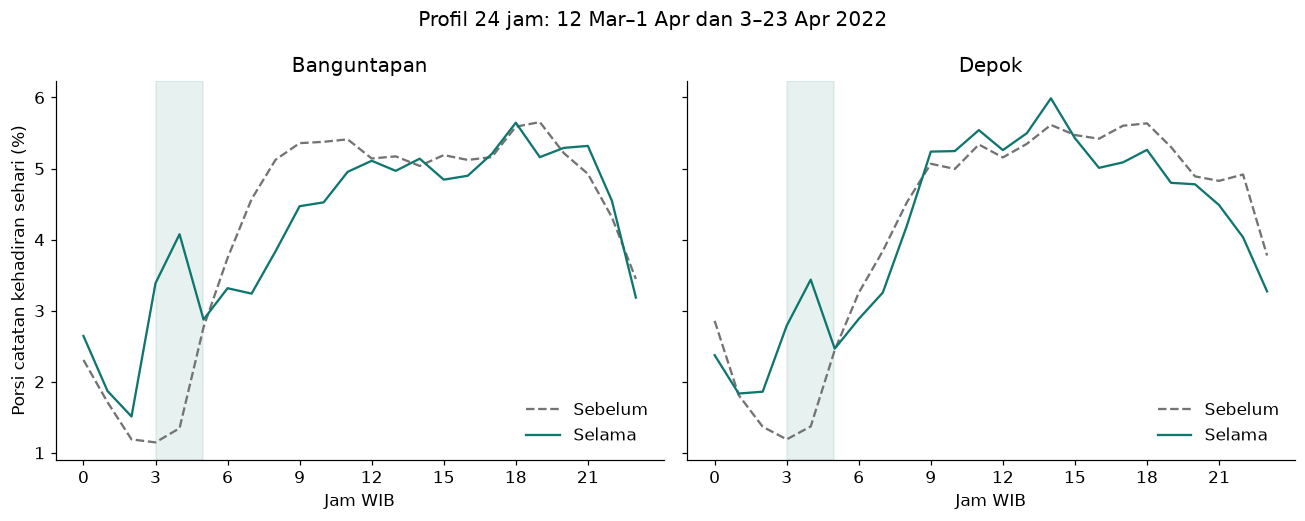

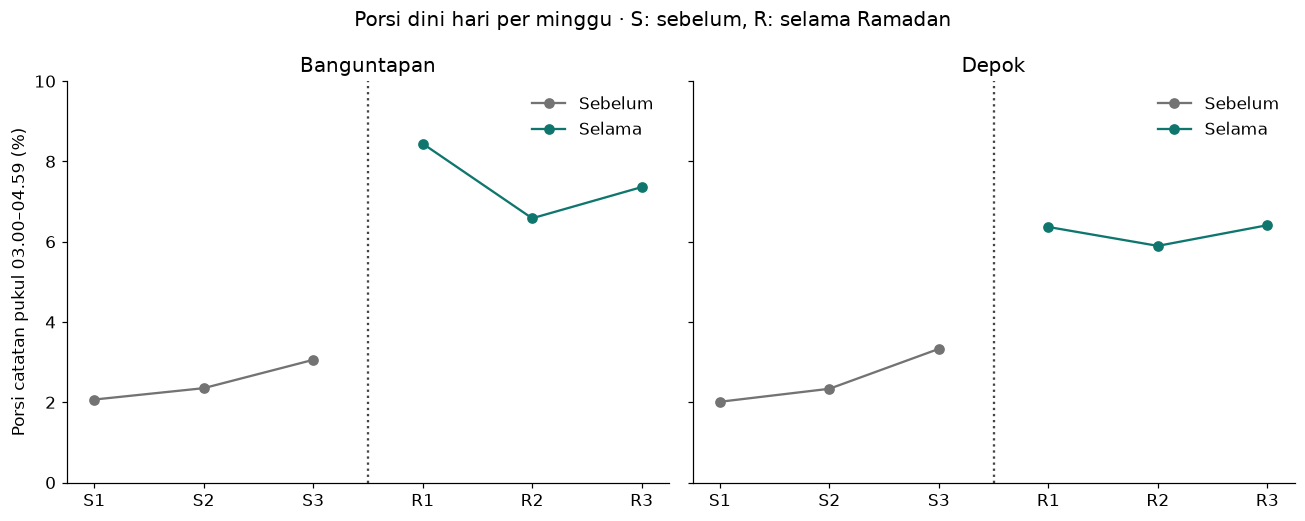

,kapanewon_code,kapanewon,period,week,share_pct,days
0,34.02.12,BANGUNTAPAN,before,1,2.07,7
1,34.02.12,BANGUNTAPAN,before,2,2.35,7
2,34.02.12,BANGUNTAPAN,before,3,3.06,7
3,34.02.12,BANGUNTAPAN,during,1,8.44,7
4,34.02.12,BANGUNTAPAN,during,2,6.58,7
5,34.02.12,BANGUNTAPAN,during,3,7.36,7
6,34.04.07,DEPOK,before,1,2.01,7
7,34.04.07,DEPOK,before,2,2.34,7
8,34.04.07,DEPOK,before,3,3.33,7
9,34.04.07,DEPOK,during,1,6.37,7


In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax,(c,row) in zip(axes,focus.iterrows()):
    for period,label,color in [('before','Sebelum',BEFORE),('during','Selama',DURING)]:
        p=r['profiles'].query('kapanewon_code == @c and period == @period')
        ax.plot(p.hour,p.share_pct,color=color,label=label,ls='--' if period=='before' else '-')
    ax.axvspan(3,4.99,alpha=.1,color=DURING);ax.set_xticks(range(0,24,3));ax.set_xlabel('Jam WIB')
    ax.set_title(row.kapanewon.title());ax.legend(frameon=False)
axes[0].set_ylabel('Porsi catatan kehadiran sehari (%)')
fig.suptitle('Profil 24 jam: 12 Mar–1 Apr dan 3–23 Apr 2022')
fig.tight_layout();save(fig,'hourly_profile');plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax,(c,row) in zip(axes,focus.iterrows()):
    for period,offset,color,label in [('before',0,BEFORE,'Sebelum'),('during',3,DURING,'Selama')]:
        p=r['weekly'].query('kapanewon_code == @c and period == @period')
        ax.plot(p.week+offset,p.share_pct,marker='o',color=color,label=label)
        if period=='during':assert p.share_pct.min()>r['weekly'].query('kapanewon_code == @c and period == "before"').share_pct.max()
    ax.set_xticks(range(1,7),['S1','S2','S3','R1','R2','R3']);ax.axvline(3.5,color='#444444',ls=':')
    ax.set_ylim(0,10);ax.set_title(row.kapanewon.title());ax.legend(frameon=False)
axes[0].set_ylabel('Porsi catatan pukul 03.00–04.59 (%)')
fig.suptitle('Porsi dini hari per minggu · S: sebelum, R: selama Ramadan')
fig.tight_layout();save(fig,'weekly');plt.show()
display(r['weekly'].round(2))

### Cocokkan ke sumber dan simpan jejak bukti

Periksa seluruh hitungan per jam untuk dua wilayah contoh pada kedua periode dan seluruh
nilai kategori Google di 42 tanggal terhadap CSV sumber. Jangan menggunakan ID individu.
Input hash dicatat untuk reproduksi; tidak ada dataset baru diunduh.

In [7]:
raw_h=ROOT/'data/raw/jogjapulse/presence_kapanewon_hourly.csv'
raw_g=ROOT/'data/raw/external/google_mobility/google_mobility_diy.csv'
rh=pd.read_csv(raw_h,parse_dates=['date'],dtype={'kapanewon_code':str})
keys=['kapanewon_code','date','hour']
mask=h.kapanewon_code.isin(RAMADAN_FOCUS_CODES)&h.date.isin(r['before'].union(r['during']))
checked=h.loc[mask,keys+['n_maids']].merge(rh[keys+['n_maids']],on=keys,validate='one_to_one',suffixes=('','_raw'))
assert len(checked)==2*42*24 and checked.n_maids.eq(checked.n_maids_raw).all()
checked['raw_total']=checked.groupby(['kapanewon_code','date']).n_maids_raw.transform('sum')
raw_ratio=(checked[checked.hour.isin([3,4])].groupby(['kapanewon_code','date']).n_maids_raw.sum()
           /checked.groupby(['kapanewon_code','date']).n_maids_raw.sum()*100)
for c in RAMADAN_FOCUS_CODES:
    for label in ['before','during']:
        assert np.isclose(raw_ratio.loc[c].reindex(r[label]).mean(),focus.loc[c,label])
rg=pd.read_csv(raw_g,parse_dates=['date']).set_index('date')
assert rg.index.is_unique and rg.sub_region_2.isna().all() and rg.sub_region_1.nunique()==1
for cat in GOOGLE_CATEGORIES:
    assert np.allclose(rg.loc[r['before'].union(r['during']),cat+'_percent_change_from_baseline'],
                       d.loc[r['before'].union(r['during']),'g_'+cat])
paths=[raw_h,raw_g,CALENDAR_CSV,PROCESSED/'hourly_kapanewon.parquet',PROCESSED/'daily_diy.parquet']
provenance={'before':[str(v.date()) for v in r['before']], 'during':[str(v.date()) for v in r['during']],
            'hours':[3,4],'equal_day_weight':True,'source_hour_rows_checked':len(checked),
            'eligible_areas':r['coverage'].loc[r['coverage'].eligible,'kapanewon_code'].tolist(),
            'input_sha256':{str(p.relative_to(ROOT)).replace('\\','/'):hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}}
(TABLES/'ramadan_provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
print(f"Cocok dengan sumber: {len(checked)} baris per jam dan 42 × 6 nilai Google. Tidak ada error pemeriksaan.")

Cocok dengan sumber: 2016 baris per jam dan 42 × 6 nilai Google. Tidak ada error pemeriksaan.
